In [1]:
import matplotlib.pyplot as plt
print(plt.rcParams["font.family"][0])
print(plt.rcParams["font.sans-serif"][0])

sans-serif
DejaVu Sans


/var/folders/50/ywp8cf6s6wn8c_hgyd1hq0m40000gn/T/ipykernel_6912/3643896653.py:46: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_labels = df.applymap(lambda x: f"{x * 100:.2f}%")


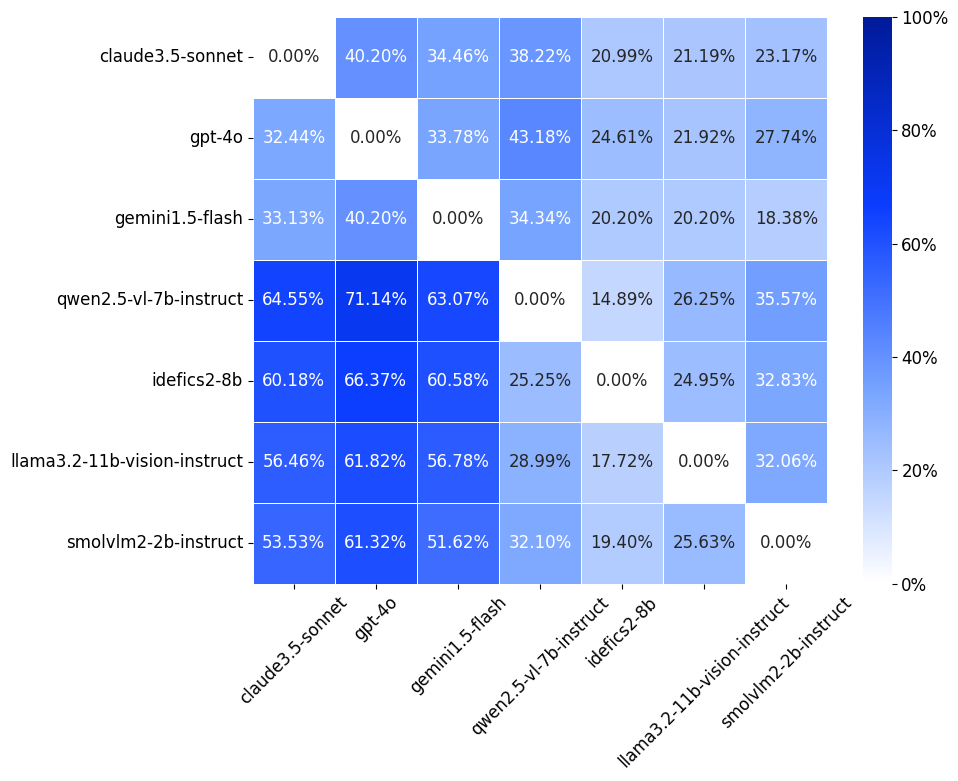

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

# ----------------------
# 1. 还原文档中的数值矩阵（7×7）
# 注：这里的数值是“百分数”（0~100）
# ----------------------
data = [
    [0.00, 40.20, 34.46, 38.22, 20.99, 21.19, 23.17],
    [32.44, 0.00, 33.78, 43.18, 24.61, 21.92, 27.74],
    [33.13, 40.20, 0.00, 34.34, 20.20, 20.20, 18.38],
    [64.55, 71.14, 63.07, 0.00, 14.89, 26.25, 35.57],
    [60.18, 66.37, 60.58, 25.25, 0.00, 24.95, 32.83],
    [56.46, 61.82, 56.78, 28.99, 17.72, 0.00, 32.06],
    [53.53, 61.32, 51.62, 32.10, 19.40, 25.63, 0.00]
]

# 行/列名字（长度=7，且顺序与矩阵一致）
row_names = [
    "claude3.5-sonnet",
    "gpt-4o",
    "gemini1.5-flash",
    "qwen2.5-vl-7b-instruct",
    "idefics2-8b",
    "llama3.2-11b-vision-instruct",
    "smolvlm2-2b-instruct",
]
col_names = row_names.copy()
assert len(row_names) == 7 and len(col_names) == 7

# 转换为Pandas DataFrame（便于标签管理）
df_pct = pd.DataFrame(
    data,
    index=row_names,
    columns=col_names,
)

# 画图用 0~1 的比例值（固定色带范围 0~1）
df = df_pct / 100.0

# 单元格显示为百分比文本
annot_labels = df.applymap(lambda x: f"{x * 100:.2f}%")

# ----------------------
# 2. 绘制热力图（0~1：白 -> 深蓝）
# ----------------------
plt.figure(figsize=(10, 8))

# 更艳丽的蓝色端点（可按需要再调）
vivid_white_to_blue = LinearSegmentedColormap.from_list(
    "vivid_white_to_blue",
    ["#ffffff", "#7aa6ff", "#0b3dff", "#001a99"],
    N=256,
)

# 全局字号（也可以分别调下面的 tick/annot）
plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

ax = sns.heatmap(
    df,
    annot=annot_labels,
    fmt="",              # annot 已经是字符串
    annot_kws={"size": 12},
    vmin=0,
    vmax=1,
    cmap=vivid_white_to_blue,
    cbar_kws={"format": PercentFormatter(xmax=1)},
    linewidths=0.5,
    linecolor="white",
)

# ----------------------
# 3. 美化
# ----------------------
ax.tick_params(axis="x", labelrotation=45, labelsize=12)
ax.tick_params(axis="y", labelrotation=0, labelsize=12)

# 色条刻度字号
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12)

plt.tight_layout()
plt.show()ze": 13,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

ax = sns.heatmap(
    df,
    annot=annot_labels,
    fmt="",              # annot 已经是字符串
    annot_kws={"size": 12},
    vmin=0,
    vmax=1,
    cmap=vivid_white_to_blue,
    cbar_kws={"format": PercentFormatter(xmax=1)},
    linewidths=0.5,
    linecolor="white",
)

# ----------------------
# 3. 美化
# ----------------------
ax.tick_params(axis="x", labelrotation=45, labelsize=12)
ax.tick_params(axis="y", labelrotation=0, labelsize=12)

# 色条刻度字号
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()


/var/folders/50/ywp8cf6s6wn8c_hgyd1hq0m40000gn/T/ipykernel_6912/2685610960.py:28: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  annot_labels = df.applymap(lambda x: f"{x * 100:.2f}")


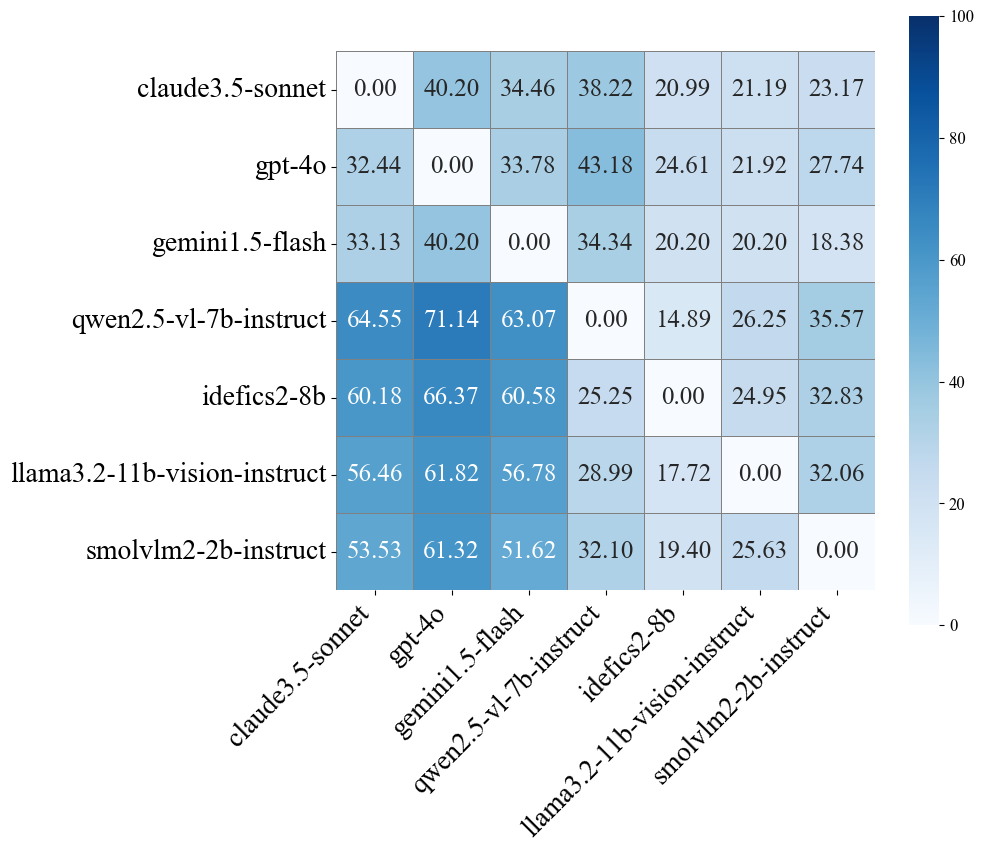

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 原始数据
data = [
    [0, 0.401980198, 0.344554455, 0.382178218, 0.20990099, 0.211881188, 0.231683168],
    [0.324384787, 0, 0.337807606, 0.431767338, 0.246085011, 0.219239374, 0.277404922],
    [0.331313131, 0.402020202, 0, 0.343434343, 0.202020202, 0.202020202, 0.183838384],
    [0.645454545, 0.711363636, 0.630681818, 0, 0.148863636, 0.2625, 0.355681818],
    [0.601796407, 0.663672655, 0.605788423, 0.25249501, 0, 0.249500998, 0.328343313],
    [0.564551422, 0.618161926, 0.567833698, 0.289934354, 0.177242888, 0, 0.320568928],
    [0.535329341, 0.613173653, 0.516167665, 0.320958084, 0.194011976, 0.256287425, 0]
]

# 模型名称
models = [
    "claude3.5-sonnet", "gpt-4o", "gemini1.5-flash",
    "qwen2.5-vl-7b-instruct", "idefics2-8b",
    "llama3.2-11b-vision-instruct", "smolvlm2-2b-instruct"
]

# 创建DataFrame（单元格内为 0~1 的比例，用于配色）
df = pd.DataFrame(data, index=models, columns=models)

# 标注：显示百分占比（0~100），不显示百分号
annot_labels = df.applymap(lambda x: f"{x * 100:.2f}")

# 设置字体
plt.rcParams.update({
    "font.size": 18,
    "font.family": "Times New Roman"
})

# 创建图像和热图
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(
    df,
    annot=annot_labels,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar=True,
    linewidths=0.5,
    linecolor="gray",
    square=True,
    ax=ax,
)

# 右侧色条：显示 0~100（数据仍为 0~1 映射）
cbar = ax.collections[0].colorbar
cbar.set_ticks(np.linspace(0, 1, 6))
cbar.set_ticklabels([0, 20, 40, 60, 80, 100])

# 设置坐标轴字体大小
ax.set_xticklabels(ax.get_xticklabels(), fontsize=20, rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), fontsize=20, rotation=0)

# 保存为PDF，去除白边
plt.tight_layout(pad=0)
plt.savefig("heatmap.pdf", format="pdf", bbox_inches='tight', pad_inches=0)



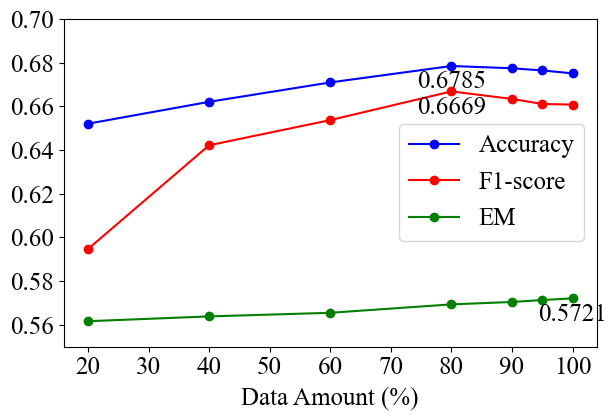

In [37]:
import matplotlib.pyplot as plt
# 设置全局字体
plt.rcParams.update({'font.size': 18, 'font.family': 'Times New Roman'})
# 数据
data = {
    # "Data Size": [20, 40, 60, 80, 90, 100],
"Data Size": [20, 40, 60, 80, 90, 95, 100],
    "Accuracy": [0.652072388, 0.66209096, 0.670965058, 0.678488033, 0.677452579, 0.676452579,0.675124792],
    # "Precision": [0.663505311, 0.682371295, 0.621186911, 0.643649473, 0.66112138, 0.640321686],
    # "Recall": [0.538817006, 0.606489185, 0.68986757, 0.691803279, 0.660510926, 0.688226528],
    "F1": [0.594695682, 0.642196447, 0.653728294, 0.66685821, 0.66341043, 0.66112138, 0.660816012, ],
    "EM": [0.561674009, 0.563876652, 0.565528634, 0.56938326, 0.570484581, 0.571354,0.572136564],
}
#
# 创建折线图
plt.figure(figsize=(6, 4))

plt.plot(data["Data Size"], data["Accuracy"], 'o-', label="Accuracy", color='b', markersize=6)
# plt.plot(data["Data Size"], data["Precision"], 'o-', label="Precision", color='g', markersize=6)
# plt.plot(data["Data Size"], data["Recall"], 'o-', label="Recall", color='r', markersize=6)
plt.plot(data["Data Size"], data["F1"], 'o-', label="F1-score", color='r', markersize=6)
plt.plot(data["Data Size"], data["EM"], 'o-', label="EM", color='g', markersize=6)

for label, values in data.items():
    if label != "Data Size":
        max_value = max(values)
        max_index = values.index(max_value)
        plt.text(data["Data Size"][max_index], max_value-0.002, f'{max_value:.4f}', fontsize=18, ha='center', va='top')

# 设置字体
plt.rcParams.update({'font.size': 18, 'font.family': 'Times New Roman'})
# 设置legend和坐标轴字体大小
plt.legend(fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
# 设置标题和标签
# plt.title('Performance Metrics vs Data Size', fontsize=18)
plt.xlabel('Data Amount (%)', fontsize=18)
# plt.ylabel('Metric Values', fontsize=18)

# 设置纵坐标范围
plt.ylim(0.55, 0.70)


# 保存为PDF
plt.tight_layout(pad=0)
plt.savefig('samples-performance.pdf', format='pdf', bbox_inches='tight')

# 显示图形
plt.show()


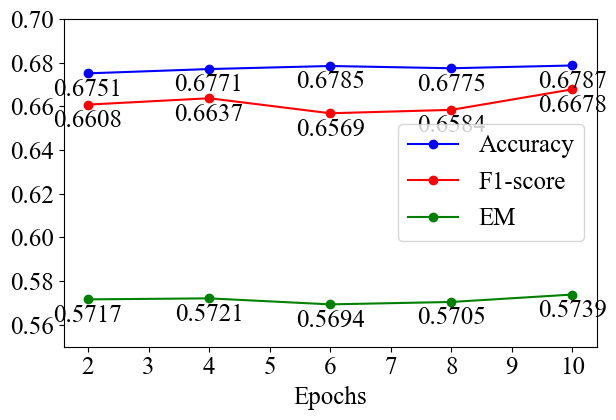

In [38]:

import matplotlib.pyplot as plt
# 设置全局字体
plt.rcParams.update({'font.size': 18, 'font.family': 'Times New Roman'})
# 数据
data = {
    # "Data Size": [20, 40, 60, 80, 90, 100],
"Data Size": [2, 4, 6, 8, 10],
    "Accuracy": [0.675124792, 0.67709096, 0.678488033, 0.677452579,0.67872388],
    # "Precision": [0.663505311, 0.682371295, 0.621186911, 0.643649473, 0.66112138, 0.640321686],
    # "Recall": [0.538817006, 0.606489185, 0.68986757, 0.691803279, 0.660510926, 0.688226528],
    "F1": [0.660816012, 0.663728294, 0.65685821, 0.65841043, 0.66782138],
    "EM": [0.571674009, 0.572136564, 0.56938326, 0.570484581,0.573876652],
}
#
# 创建折线图
plt.figure(figsize=(6, 4))

plt.plot(data["Data Size"], data["Accuracy"], 'o-', label="Accuracy", color='b', markersize=6)
# plt.plot(data["Data Size"], data["Precision"], 'o-', label="Precision", color='g', markersize=6)
# plt.plot(data["Data Size"], data["Recall"], 'o-', label="Recall", color='r', markersize=6)
plt.plot(data["Data Size"], data["F1"], 'o-', label="F1-score", color='r', markersize=6)
plt.plot(data["Data Size"], data["EM"], 'o-', label="EM", color='g', markersize=6)

# for label, values in data.items():
#     if label != "Data Size":
#         max_value = max(values)
#         max_index = values.index(max_value)
#         plt.text(data["Data Size"][max_index], max_value-0.002, f'{max_value:.4f}', fontsize=18, ha='center', va='top')

for label, values in data.items():
    if label != "Data Size":
        for i, value in enumerate(values):
            plt.text(data["Data Size"][i], value - 0.002, f'{value:.4f}', fontsize=18, ha='center', va='top')

# 设置字体
plt.rcParams.update({'font.size': 18, 'font.family': 'Times New Roman'})
# 设置legend和坐标轴字体大小
plt.legend(fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
# 设置标题和标签
# plt.title('Performance Metrics vs Data Size', fontsize=18)
plt.xlabel('Epochs', fontsize=18)
# plt.ylabel('Metric Values', fontsize=18)

# 设置纵坐标范围
plt.ylim(0.55, 0.70)


# 保存为PDF
plt.tight_layout(pad=0)
plt.savefig('id_performance_epochs.pdf', format='pdf', bbox_inches='tight')

# 显示图形
plt.show()


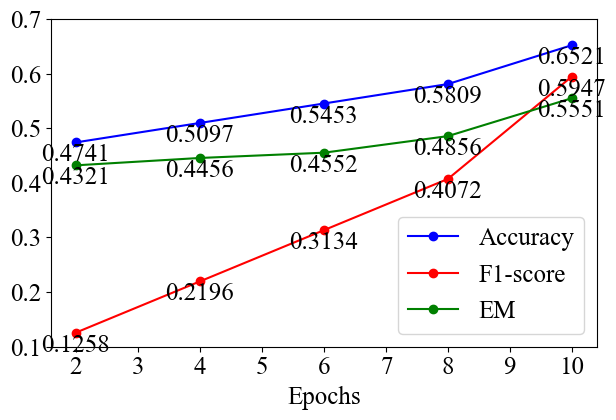

In [36]:

import matplotlib.pyplot as plt
# 设置全局字体
plt.rcParams.update({'font.size': 18, 'font.family': 'Times New Roman'})
# 数据
data = {
"Data Size": [2, 4, 6, 8, 10],
    "Accuracy": [0.474082702, 0.509680639, 0.545278576, 0.580876514, 0.652072388],
    "F1": [0.125847047, 0.219616774, 0.313386501, 0.407156228, 0.594695682],
    "EM": [0.4321, 0.445572687, 0.45522467, 0.485575365, 0.555066079]
}
#
# 创建折线图
plt.figure(figsize=(6, 4))

plt.plot(data["Data Size"], data["Accuracy"], 'o-', label="Accuracy", color='b', markersize=6)
# plt.plot(data["Data Size"], data["Precision"], 'o-', label="Precision", color='g', markersize=6)
# plt.plot(data["Data Size"], data["Recall"], 'o-', label="Recall", color='r', markersize=6)
plt.plot(data["Data Size"], data["F1"], 'o-', label="F1-score", color='r', markersize=6)
plt.plot(data["Data Size"], data["EM"], 'o-', label="EM", color='g', markersize=6)

# for label, values in data.items():
#     if label != "Data Size":
#         max_value = max(values)
#         max_index = values.index(max_value)
#         plt.text(data["Data Size"][max_index], max_value-0.002, f'{max_value:.4f}', fontsize=18, ha='center', va='top')

for label, values in data.items():
    if label != "Data Size":
        for i, value in enumerate(values):
            plt.text(data["Data Size"][i], value - 0.002, f'{value:.4f}', fontsize=18, ha='center', va='top')

# 设置字体
plt.rcParams.update({'font.size': 18, 'font.family': 'Times New Roman'})
# 设置legend和坐标轴字体大小
plt.legend(fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
# 设置标题和标签
# plt.title('Performance Metrics vs Data Size', fontsize=18)
plt.xlabel('Epochs', fontsize=18)
# plt.ylabel('Metric Values', fontsize=18)

# 设置纵坐标范围
plt.ylim(0.1, 0.70)


# 保存为PDF
plt.tight_layout(pad=0)
plt.savefig('ood_performance_epochs.pdf', format='pdf', bbox_inches='tight')

# 显示图形
plt.show()
